<a href="https://colab.research.google.com/github/luisferdm6/02-hotel-booking-demand-analytics/blob/main/01_hotel_booking_cleaning_and_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hotel Booking Demand & Revenue Risk Analysis
### End-to-End Data Cleansing, Behavioral Cancellation Diagnostics, and Analytical OLAP Queries

**Analyst:** Luis Fernando Duardo Medina  
**Dataset:** TidyTuesday Hotel Booking Demand (119,390 raw transactions)  
**Tech Stack:** Python, Pandas, DuckDB (SQL), Seaborn, Matplotlib

## 1. Environment Setup, Data Ingestion & Vectorized Cleansing
Load the raw hotel reservation dataset, inspect structural missingness, impute null values, drop uninformative columns (`company` >94% missing), cast numeric identifiers to integers, and engineer temporal attributes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import duckdb

# Load raw hotel bookings dataset
dataset_url = "https://raw.githubusercontent.com/Rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
hotel_df = pd.read_csv(dataset_url)

print(f"Initial dataset shape: {hotel_df.shape}")
hotel_df.head()

Initial dataset shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [2]:
# Inspect data types and identify columns with missing values
hotel_df.info()

null_counts = hotel_df.isnull().sum()
print("\nColumns with missing values before cleansing:")
print(null_counts[null_counts > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [3]:
# Vectorized null imputation, feature pruning, and integer type casting
hotel_df['children'] = hotel_df['children'].fillna(0).astype(int)
hotel_df['country'] = hotel_df['country'].fillna('Unknown')
hotel_df['agent'] = hotel_df['agent'].fillna(0).astype(int)
hotel_df = hotel_df.drop(columns=['company'], errors='ignore')

# Temporal feature engineering
hotel_df['reservation_status_date'] = pd.to_datetime(hotel_df['reservation_status_date'])
hotel_df['status_year'] = hotel_df['reservation_status_date'].dt.year
hotel_df['status_day_name'] = hotel_df['reservation_status_date'].dt.day_name()

print(f"Total remaining null values in dataset: {hotel_df.isna().sum().sum()}")
hotel_df[['reservation_status_date', 'status_year', 'status_day_name', 'children', 'agent']].head()

Total remaining null values in dataset: 0


,reservation_status_date,status_year,status_day_name,children,agent
0,2015-07-01,2015,Wednesday,0,0
1,2015-07-01,2015,Wednesday,0,0
2,2015-07-02,2015,Thursday,0,0
3,2015-07-02,2015,Thursday,0,304
4,2015-07-03,2015,Friday,0,240


## 2. Pricing Anomaly Detection & Outlier Depuration
Audit the Average Daily Rate (`adr`) distribution across commercial segments, isolate erroneous extreme records (`adr > $5,000` and `adr < $0`), and filter the dataset to retain clean, valid transactions.

In [4]:
# Inspect raw ADR range (min, mean, max) across commercial distribution channels
raw_adr_summary_df = (
    hotel_df.groupby('market_segment')['adr']
    .agg(['min', 'mean', 'max'])
    .reset_index()
    .sort_values(by='mean', ascending=False)
)
raw_adr_summary_df[['min', 'mean', 'max']] = raw_adr_summary_df[['min', 'mean', 'max']].map('${:.2f}'.format)
raw_adr_summary_df

,market_segment,min,mean,max
6,Online TA,$0.00,$117.20,$450.00
3,Direct,$0.00,$115.45,$451.50
0,Aviation,$0.00,$100.14,$193.50
5,Offline TA/TO,$0.00,$87.35,$5400.00
4,Groups,$-6.38,$79.48,$367.00
2,Corporate,$0.00,$69.36,$508.00
7,Undefined,$12.00,$15.00,$18.00
1,Complementary,$0.00,$2.89,$170.00


In [5]:
# Identify pricing anomalies (extreme high > $5,000 or negative ADR < $0)
pricing_anomalies_df = hotel_df[(hotel_df['adr'] > 5000) | (hotel_df['adr'] < 0)][
    ['hotel', 'is_canceled', 'reserved_room_type', 'adults', 'children', 'adr']
]
print("Detected pricing anomalies:")
display(pricing_anomalies_df)

# Filter out anomalies and verify clean ADR distribution
hotel_df = hotel_df[(hotel_df['adr'] >= 0) & (hotel_df['adr'] < 5000)].copy()
print(f"\nClean dataset shape: {hotel_df.shape}")

clean_adr_summary_df = (
    hotel_df.groupby('market_segment')['adr']
    .agg(['min', 'mean', 'max'])
    .reset_index()
    .sort_values(by='mean', ascending=False)
)
clean_adr_summary_df[['min', 'mean', 'max']] = clean_adr_summary_df[['min', 'mean', 'max']].map('${:.2f}'.format)
clean_adr_summary_df

Detected pricing anomalies:


,hotel,is_canceled,reserved_room_type,adults,children,adr
14969,Resort Hotel,0,A,2,0,-6.38
48515,City Hotel,1,A,2,0,5400.00



Clean dataset shape: (119388, 33)


,market_segment,min,mean,max
6,Online TA,$0.00,$117.20,$450.00
3,Direct,$0.00,$115.45,$451.50
0,Aviation,$0.00,$100.14,$193.50
5,Offline TA/TO,$0.00,$87.14,$510.00
4,Groups,$0.00,$79.48,$367.00
2,Corporate,$0.00,$69.36,$508.00
7,Undefined,$12.00,$15.00,$18.00
1,Complementary,$0.00,$2.89,$170.00


## 3. Property-Level KPIs, Stay Duration & Revenue Leakage Analysis
Evaluate Average Daily Rate (`adr`), Average Length of Stay (`total_stay`), realized room revenue from completed stays, and gross revenue lost to cancellations across `City Hotel` and `Resort Hotel`.

In [6]:
# Average Daily Rate (ADR) segmented by hotel type and cancellation status
adr_by_status_df = (
    hotel_df.assign(canceled_label=hotel_df['is_canceled'].map({0: 'No', 1: 'Yes'}))
    .groupby(['hotel', 'canceled_label'])['adr']
    .mean()
    .map('${:.2f}'.format)
    .reset_index()
)
adr_by_status_df

,hotel,canceled_label,adr
0,City Hotel,No,$105.75
1,City Hotel,Yes,$104.53
2,Resort Hotel,No,$90.79
3,Resort Hotel,Yes,$105.79


In [7]:
# Engineer total length of stay (nights) and total booking revenue
hotel_df['total_stay'] = hotel_df['stays_in_week_nights'] + hotel_df['stays_in_weekend_nights']
hotel_df['total_cost'] = hotel_df['total_stay'] * hotel_df['adr']

# Stay duration statistics (min, mean, max nights) per property type
stay_duration_df = hotel_df.groupby('hotel')['total_stay'].agg(['min', 'mean', 'max']).reset_index()
stay_duration_df['mean'] = stay_duration_df['mean'].round(2)
stay_duration_df

,hotel,min,mean,max
0,City Hotel,0,2.98,57
1,Resort Hotel,0,4.32,69


In [8]:
# Realized room revenue (confirmed stays) vs. Gross revenue lost to cancellations
realized_revenue_df = (
    hotel_df[hotel_df['is_canceled'] == 0]
    .groupby('hotel')['total_cost']
    .sum()
    .map('${:,.2f}'.format)
    .reset_index(name='realized_revenue_usd')
)

lost_revenue_df = (
    hotel_df[hotel_df['is_canceled'] == 1]
    .groupby('hotel')['total_cost']
    .sum()
    .map('${:,.2f}'.format)
    .reset_index(name='lost_revenue_usd')
)

hotel_cancellation_df = (
    hotel_df.groupby('hotel')['is_canceled']
    .mean()
    .map('{:.2%}'.format)
    .reset_index(name='cancellation_rate')
)

property_financial_summary_df = (
    realized_revenue_df
    .merge(lost_revenue_df, on='hotel')
    .merge(hotel_cancellation_df, on='hotel')
)
property_financial_summary_df

,hotel,realized_revenue_usd,lost_revenue_usd,cancellation_rate
0,City Hotel,"$14,394,410.18","$10,879,659.78",41.73%
1,Resort Hotel,"$11,601,914.03","$5,842,177.34",27.76%


## 4. Distribution Channel Economics & Cancellation Risk
Analyze booking volume, cancellation proportions, and property-level vulnerability across commercial distribution segments (`Online TA`, `Offline TA/TO`, `Groups`, `Direct`, `Corporate`).

In [9]:
# Consolidated booking volume, cancellations, and cancellation rate by market segment
channel_summary_df = (
    hotel_df.groupby('market_segment')
    .agg(
        total_bookings=('is_canceled', 'count'),
        cancellations=('is_canceled', 'sum'),
        cancellation_rate=('is_canceled', 'mean')
    )
    .sort_values(by='total_bookings', ascending=False)
    .reset_index()
)

channel_summary_df['cancellation_rate_pct'] = channel_summary_df['cancellation_rate'].map('{:.2%}'.format)
channel_summary_df[['market_segment', 'total_bookings', 'cancellations', 'cancellation_rate_pct']]

,market_segment,total_bookings,cancellations,cancellation_rate_pct
0,Online TA,56477,20739,36.72%
1,Offline TA/TO,24218,8310,34.31%
2,Groups,19810,12097,61.07%
3,Direct,12606,1934,15.34%
4,Corporate,5295,992,18.73%
5,Complementary,743,97,13.06%
6,Aviation,237,52,21.94%
7,Undefined,2,2,100.00%


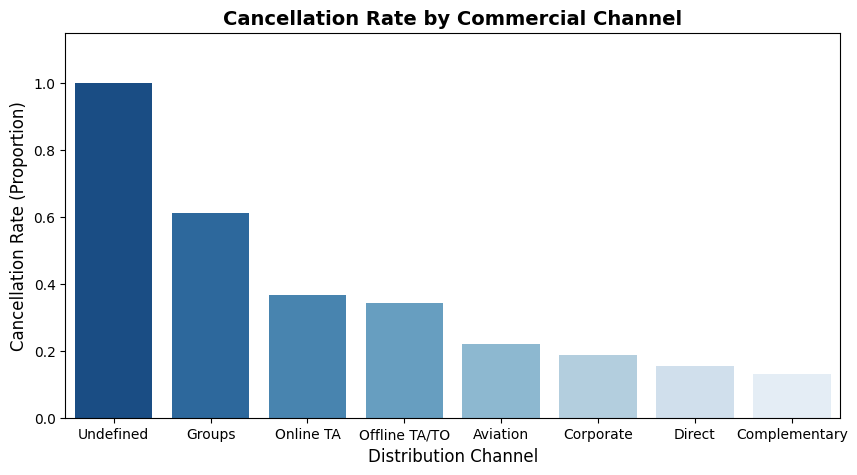

In [10]:
# Plot overall cancellation rate by commercial distribution channel
channel_plot_df = (
    hotel_df.groupby('market_segment')['is_canceled']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=channel_plot_df,
    x='market_segment',
    y='is_canceled',
    palette='Blues_r',
    hue='market_segment',
    legend=False
)
plt.title('Cancellation Rate by Commercial Channel', fontsize=14, fontweight='bold')
plt.xlabel('Distribution Channel', fontsize=12)
plt.ylabel('Cancellation Rate (Proportion)', fontsize=12)
plt.ylim(0, 1.15)
plt.show()

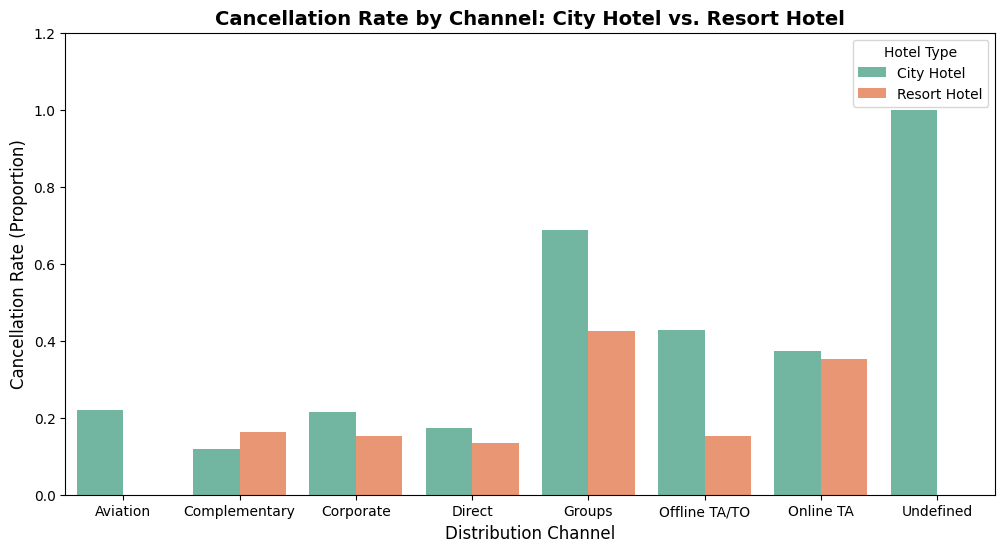

In [11]:
# Compare channel cancellation risk between City Hotel and Resort Hotel
channel_hotel_comparison_df = (
    hotel_df.groupby(['market_segment', 'hotel'])['is_canceled']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=channel_hotel_comparison_df,
    x='market_segment',
    y='is_canceled',
    hue='hotel',
    palette='Set2'
)
plt.title('Cancellation Rate by Channel: City Hotel vs. Resort Hotel', fontsize=14, fontweight='bold')
plt.xlabel('Distribution Channel', fontsize=12)
plt.ylabel('Cancellation Rate (Proportion)', fontsize=12)
plt.ylim(0, 1.2)
plt.legend(title='Hotel Type')
plt.show()

## 5. Seasonality, Pricing Dynamics & Guest Origin Markets
Examine monthly Average Daily Rate (`adr`) trends, arrival volume seasonality, and top international origin markets for confirmed hotel stays.

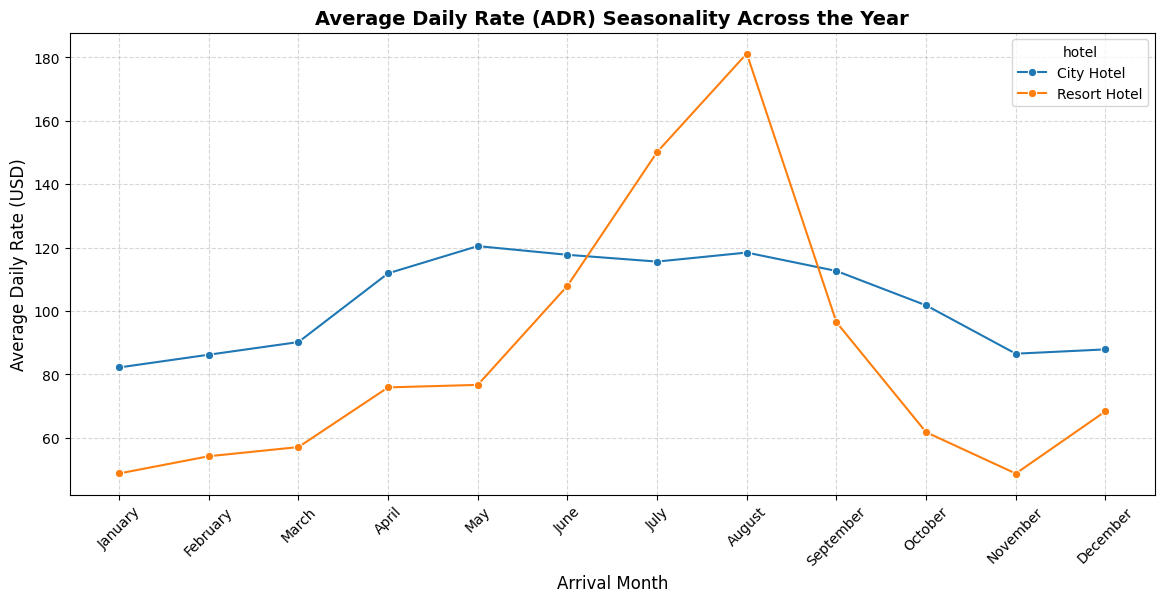

In [12]:
# Filter confirmed stays and enforce chronological month ordering
confirmed_bookings_df = hotel_df[hotel_df['is_canceled'] == 0].copy()

month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]
confirmed_bookings_df['arrival_date_month'] = pd.Categorical(
    confirmed_bookings_df['arrival_date_month'],
    categories=month_order,
    ordered=True
)

monthly_adr_by_hotel_df = (
    confirmed_bookings_df.groupby(['hotel', 'arrival_date_month'], observed=True)['adr']
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_adr_by_hotel_df,
    x='arrival_date_month',
    y='adr',
    hue='hotel',
    marker='o'
)
plt.title('Average Daily Rate (ADR) Seasonality Across the Year', fontsize=14, fontweight='bold')
plt.xlabel('Arrival Month', fontsize=12)
plt.ylabel('Average Daily Rate (USD)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [13]:
# Monthly confirmed guest arrivals and realized ADR summary
monthly_occupancy_df = (
    confirmed_bookings_df.groupby('arrival_date_month', observed=True)
    .agg(
        total_confirmed_bookings=('hotel', 'count'),
        average_adr=('adr', 'mean')
    )
    .reset_index()
)
monthly_occupancy_df['average_adr'] = monthly_occupancy_df['average_adr'].map('${:.2f}'.format)
monthly_occupancy_df

,arrival_date_month,total_confirmed_bookings,average_adr
0,January,4122,$67.00
1,February,5372,$72.42
2,March,6644,$77.34
3,April,6565,$97.88
4,May,7114,$104.84
5,June,6404,$114.59
6,July,7919,$129.25
7,August,8638,$142.09
8,September,6392,$107.28
9,October,6914,$86.83


,Country,Total_Bookings
0,PRT,21071
1,GBR,9675
2,FRA,8481
3,ESP,6391
4,DEU,6069


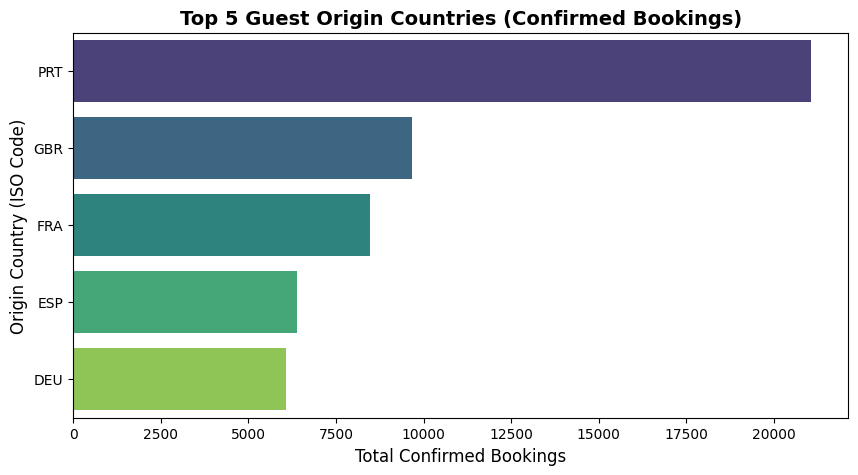

In [14]:
# Top 5 guest origin countries for confirmed bookings
top_countries_df = confirmed_bookings_df['country'].value_counts().head(5).reset_index()
top_countries_df.columns = ['Country', 'Total_Bookings']
display(top_countries_df)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_countries_df,
    x='Total_Bookings',
    y='Country',
    palette='viridis',
    hue='Country',
    legend=False
)
plt.title('Top 5 Guest Origin Countries (Confirmed Bookings)', fontsize=14, fontweight='bold')
plt.xlabel('Total Confirmed Bookings', fontsize=12)
plt.ylabel('Origin Country (ISO Code)', fontsize=12)
plt.show()

## 6. Behavioral Commitment Indicators & The "Non-Refundable" Deposit Paradox
Investigate how booking lead time, deposit policies, customer loyalty (`is_repeated_guest`), special requests, and car parking allocations influence cancellation behavior.

In [15]:
# Lead time (days in advance) by cancellation status and market segment
lead_time_by_status_df = (
    hotel_df.assign(canceled_label=hotel_df['is_canceled'].map({0: 'Confirmed', 1: 'Canceled'}))
    .groupby('canceled_label')['lead_time']
    .agg(['mean', 'median'])
    .round(2)
    .reset_index()
)
display(lead_time_by_status_df)

lead_time_by_segment_df = (
    hotel_df.groupby('market_segment')['lead_time']
    .mean()
    .sort_values(ascending=False)
    .round(2)
    .reset_index(name='avg_lead_time_days')
)
display(lead_time_by_segment_df)

,canceled_label,mean,median
0,Canceled,144.85,113.0
1,Confirmed,79.98,45.0


,market_segment,avg_lead_time_days
0,Groups,186.97
1,Offline TA/TO,135.01
2,Online TA,83.00
3,Direct,49.86
4,Corporate,22.13
5,Complementary,13.29
6,Aviation,4.44
7,Undefined,1.50


In [16]:
# Deposit policy analysis and cross-tabulation with market segments
deposit_summary_df = (
    hotel_df.groupby('deposit_type')
    .agg(
        total_bookings=('is_canceled', 'count'),
        cancellations=('is_canceled', 'sum'),
        cancellation_rate=('is_canceled', 'mean')
    )
    .sort_values(by='total_bookings', ascending=False)
    .reset_index()
)
deposit_summary_df['cancellation_rate'] = deposit_summary_df['cancellation_rate'].map('{:.2%}'.format)
display(deposit_summary_df)

# Cross-tabulation explaining the 'Non Refund' anomaly via wholesale Groups and Offline TA/TO
deposit_segment_crosstab = pd.crosstab(hotel_df['market_segment'], hotel_df['deposit_type'])
display(deposit_segment_crosstab)

,deposit_type,total_bookings,cancellations,cancellation_rate
0,No Deposit,104640,29694,28.38%
1,Non Refund,14586,14493,99.36%
2,Refundable,162,36,22.22%


deposit_type,No Deposit,Non Refund,Refundable
market_segment,,,
Aviation,237,0,0
Complementary,743,0,0
Corporate,4957,334,4
Direct,12581,19,6
Groups,10508,9172,130
Offline TA/TO,19209,5005,4
Online TA,56403,56,18
Undefined,2,0,0


In [17]:
# Guest loyalty (Repeated vs. First-Time Guests) and behavioral commitment indicators
loyalty_summary_df = (
    hotel_df.groupby('is_repeated_guest')
    .agg(
        total_bookings=('is_canceled', 'count'),
        cancellations=('is_canceled', 'sum'),
        cancellation_rate=('is_canceled', 'mean')
    )
    .reset_index()
)
loyalty_summary_df['guest_profile'] = loyalty_summary_df['is_repeated_guest'].map({0: 'First-Time', 1: 'Repeated'})
loyalty_summary_df['booking_share'] = (loyalty_summary_df['total_bookings'] / len(hotel_df)).map('{:.2%}'.format)
loyalty_summary_df['cancellation_rate'] = loyalty_summary_df['cancellation_rate'].map('{:.2%}'.format)
display(loyalty_summary_df[['guest_profile', 'total_bookings', 'booking_share', 'cancellations', 'cancellation_rate']])

# Special requests vs. cancellation rate
special_requests_cancel_df = (
    hotel_df.groupby('total_of_special_requests')['is_canceled']
    .mean()
    .map('{:.2%}'.format)
    .reset_index(name='cancellation_rate')
)
display(special_requests_cancel_df)

# Required car parking spaces vs. cancellation rate
parking_cancel_df = (
    hotel_df.groupby('required_car_parking_spaces')['is_canceled']
    .mean()
    .map('{:.2%}'.format)
    .reset_index(name='cancellation_rate')
)
display(parking_cancel_df)

,guest_profile,total_bookings,booking_share,cancellations,cancellation_rate
0,First-Time,115579,96.81%,43671,37.78%
1,Repeated,3809,3.19%,552,14.49%


,total_of_special_requests,cancellation_rate
0,0,47.72%
1,1,22.02%
2,2,22.10%
3,3,17.86%
4,4,10.59%
5,5,5.00%


,required_car_parking_spaces,cancellation_rate
0,0,39.49%
1,1,0.00%
2,2,0.00%
3,3,0.00%
4,8,0.00%


## 7. Analytical OLAP Queries & Revenue Modeling with DuckDB (SQL)
Leverage in-memory DuckDB SQL to execute multi-dimensional aggregations, `CASE WHEN` lead-time segmentation, Common Table Expressions (CTEs), and average ticket calculations.

In [18]:
# Consolidated property KPIs and weekday/weekend night breakdown via SQL
hotel_kpis_sql = duckdb.sql("""
SELECT
    hotel,
    COUNT(*) AS total_bookings,
    SUM(is_canceled) AS total_canceled,
    ROUND(AVG(adr), 2) AS average_adr,
    SUM(CASE WHEN is_canceled = 0 THEN stays_in_weekend_nights ELSE 0 END) AS confirmed_weekend_nights,
    SUM(CASE WHEN is_canceled = 0 THEN stays_in_week_nights ELSE 0 END) AS confirmed_week_nights
FROM hotel_df
GROUP BY hotel
ORDER BY total_bookings DESC
""").df()

hotel_kpis_sql

,hotel,total_bookings,total_canceled,average_adr,confirmed_weekend_nights,confirmed_week_nights
0,City Hotel,79329,33101.0,105.24,37014.0,98139.0
1,Resort Hotel,40059,11122.0,94.96,32809.0,87068.0


In [19]:
# Annual confirmed bookings, total adults hosted, and average ADR by arrival year
annual_performance_sql = duckdb.sql("""
SELECT
    arrival_date_year,
    COUNT(*) AS confirmed_bookings,
    SUM(adults) AS total_adults,
    ROUND(AVG(adr), 2) AS average_adr
FROM hotel_df
WHERE is_canceled = 0
GROUP BY arrival_date_year
ORDER BY arrival_date_year DESC
""").df()

annual_performance_sql

,arrival_date_year,confirmed_bookings,total_adults,average_adr
0,2017,24941,46035.0,111.32
1,2016,36370,66771.0,96.52
2,2015,13854,24726.0,88.71


In [20]:
# Segment confirmed bookings by lead-time window ('Last Minute', 'Early Bird', 'Long Term')
lead_time_segments_sql = duckdb.sql("""
SELECT
    CASE
        WHEN lead_time < 7 THEN 'Last Minute (<7 days)'
        WHEN lead_time <= 30 THEN 'Early Bird (7-30 days)'
        ELSE 'Long Term (>30 days)'
    END AS booking_horizon,
    COUNT(*) AS confirmed_bookings,
    ROUND(AVG(adr), 2) AS average_adr
FROM hotel_df
WHERE is_canceled = 0
GROUP BY booking_horizon
ORDER BY confirmed_bookings DESC
""").df()

lead_time_segments_sql

,booking_horizon,confirmed_bookings,average_adr
0,Long Term (>30 days),43644,102.94
1,Last Minute (<7 days),16685,89.00
2,Early Bird (7-30 days),14836,103.66


In [21]:
# Representative commercial channels (>1,000 confirmed bookings) and CTE property filtering
major_channels_sql = duckdb.sql("""
SELECT
    market_segment,
    COUNT(*) AS confirmed_bookings,
    ROUND(AVG(adr), 2) AS average_adr
FROM hotel_df
WHERE is_canceled = 0
GROUP BY market_segment
HAVING COUNT(*) > 1000
ORDER BY confirmed_bookings DESC
""").df()
display(major_channels_sql)

# Common Table Expression (CTE) evaluating confirmed volume and lead time per hotel
confirmed_hotel_cte_sql = duckdb.sql("""
WITH confirmed_hotels AS (
    SELECT
        hotel,
        COUNT(*) AS total_confirmed,
        ROUND(AVG(lead_time), 2) AS avg_lead_time_days,
        ROUND(AVG(adr), 2) AS average_adr
    FROM hotel_df
    WHERE is_canceled = 0
    GROUP BY hotel
)
SELECT *
FROM confirmed_hotels
WHERE total_confirmed > 20000
ORDER BY total_confirmed DESC
""").df()
display(confirmed_hotel_cte_sql)

,market_segment,confirmed_bookings,average_adr
0,Online TA,35738,113.86
1,Offline TA/TO,15908,83.42
2,Direct,10672,113.88
3,Groups,7713,77.14
4,Corporate,4303,67.11


,hotel,total_confirmed,avg_lead_time_days,average_adr
0,City Hotel,46228,80.70,105.75
1,Resort Hotel,28937,78.83,90.79


In [22]:
# Total realized lodging revenue and average ticket per confirmed booking by property
hotel_revenue_ticket_sql = duckdb.sql("""
SELECT
    hotel,
    PRINTF('%,d', COUNT(*)) AS confirmed_bookings,
    PRINTF('$%,.2f', SUM(adr * (stays_in_week_nights + stays_in_weekend_nights))) AS total_realized_revenue,
    PRINTF('$%,.2f', SUM(adr * (stays_in_week_nights + stays_in_weekend_nights)) / COUNT(*)) AS avg_ticket_per_booking
FROM hotel_df
WHERE is_canceled = 0
GROUP BY hotel
ORDER BY SUM(adr * (stays_in_week_nights + stays_in_weekend_nights)) DESC
""").df()

hotel_revenue_ticket_sql

,hotel,confirmed_bookings,total_realized_revenue,avg_ticket_per_booking
0,City Hotel,"46,228","$14,394,410.18",$311.38
1,Resort Hotel,"28,937","$11,601,914.03",$400.94


## 8. Relational Catalog Joins, Referential Integrity Auditing & Revenue Visualization
Join transaction records against master reference catalogs (`meal_catalog_df` and `deposit_catalog_df`), run automated `LEFT JOIN` and `COALESCE` audits to detect unmapped orphan codes, and visualize the multidimensional revenue distribution by meal package and hotel type.

In [23]:
# Master Meal Plan Catalog and relational INNER JOIN revenue aggregation
meal_catalog_df = pd.DataFrame({
    'meal_code': ['BB', 'HB', 'FB', 'SC', 'Undefined'],
    'meal_plan': ['Bed & Breakfast', 'Half Board', 'Full Board', 'Self Catering', 'Undefined']
})

meal_plan_revenue_sql = duckdb.sql("""
SELECT
    cat.meal_plan,
    PRINTF('%,d', COUNT(*)) AS confirmed_bookings,
    PRINTF('$%,.2f', SUM(r.adr * (r.stays_in_week_nights + r.stays_in_weekend_nights))) AS total_revenue
FROM hotel_df AS r
INNER JOIN meal_catalog_df AS cat
    ON r.meal = cat.meal_code
WHERE r.is_canceled = 0
GROUP BY cat.meal_plan
ORDER BY SUM(r.adr * (r.stays_in_week_nights + r.stays_in_weekend_nights)) DESC
""").df()

meal_plan_revenue_sql

,meal_plan,confirmed_bookings,total_revenue
0,Bed & Breakfast,"57,799","$18,671,044.54"
1,Half Board,"9,479","$5,034,459.67"
2,Self Catering,"6,684","$1,677,654.02"
3,Undefined,883,"$381,490.80"
4,Full Board,320,"$231,675.18"


In [24]:
# Automated referential integrity audit function for catalog validation
def audit_catalog_integrity(
    bookings_table: pd.DataFrame,
    catalog_table: pd.DataFrame,
    fk_col: str,
    pk_col: str
) -> pd.DataFrame | None:
    """Detect unmapped or orphan foreign key codes against a master reference catalog."""
    orphan_report_df = duckdb.sql(f"""
        SELECT
            r.{fk_col} AS orphan_code,
            PRINTF('%,d', COUNT(*)) AS affected_bookings
        FROM bookings_table AS r
        LEFT JOIN catalog_table AS cat
            ON r.{fk_col} = cat.{pk_col}
        WHERE cat.{pk_col} IS NULL
        GROUP BY r.{fk_col}
        ORDER BY COUNT(*) DESC
    """).df()

    if len(orphan_report_df) == 0:
        print(f"Audit Passed [{fk_col}]: 100% Referential Integrity. All codes are registered.")
        return None
    else:
        print(f"Operational Alert [{fk_col}]: Detected {len(orphan_report_df)} orphan codes.")
        return orphan_report_df

# 1. Audit complete master meal catalog
audit_catalog_integrity(hotel_df, meal_catalog_df, 'meal', 'meal_code')
print("-" * 65)

# 2. Simulate incomplete meal catalog to test orphan detection and SQL COALESCE fallback
incomplete_meal_catalog_df = pd.DataFrame({
    'meal_code': ['BB', 'HB', 'FB'],
    'meal_plan': ['Bed & Breakfast', 'Half Board', 'Full Board']
})
display(audit_catalog_integrity(hotel_df, incomplete_meal_catalog_df, 'meal', 'meal_code'))
print("-" * 65)

# 3. Audit deposit type master catalog
deposit_catalog_df = pd.DataFrame({
    'official_deposit_type': ['No Deposit', 'Non Refund', 'Refundable']
})
audit_catalog_integrity(hotel_df, deposit_catalog_df, 'deposit_type', 'official_deposit_type')

# 4. Demonstrate defensive reporting with SQL COALESCE on incomplete catalog
coalesce_audit_sql = duckdb.sql("""
SELECT
    r.meal AS original_code,
    COALESCE(cat.meal_plan, 'Unregistered Code') AS standardized_meal_plan,
    PRINTF('%,d', COUNT(*)) AS total_bookings
FROM hotel_df AS r
LEFT JOIN incomplete_meal_catalog_df AS cat
    ON r.meal = cat.meal_code
GROUP BY r.meal, cat.meal_plan
ORDER BY COUNT(*) DESC
""").df()
display(coalesce_audit_sql)

Audit Passed [meal]: 100% Referential Integrity. All codes are registered.
-----------------------------------------------------------------
Operational Alert [meal]: Detected 2 orphan codes.


,orphan_code,affected_bookings
0,SC,"10,650"
1,Undefined,"1,169"


-----------------------------------------------------------------
Audit Passed [deposit_type]: 100% Referential Integrity. All codes are registered.


,original_code,standardized_meal_plan,total_bookings
0,BB,Bed & Breakfast,"92,308"
1,HB,Half Board,"14,463"
2,SC,Unregistered Code,"10,650"
3,Undefined,Unregistered Code,"1,169"
4,FB,Full Board,798


,hotel,meal_plan,confirmed_bookings,total_revenue
0,City Hotel,Bed & Breakfast,"35,638","$11,334,961.83"
1,City Hotel,Self Catering,"6,601","$1,675,424.09"
2,City Hotel,Half Board,"3,980","$1,383,602.76"
3,City Hotel,Full Board,9,$421.50
4,Resort Hotel,Bed & Breakfast,"22,161","$7,336,082.71"
5,Resort Hotel,Half Board,"5,499","$3,650,856.91"
6,Resort Hotel,Undefined,883,"$381,490.80"
7,Resort Hotel,Full Board,311,"$231,253.68"
8,Resort Hotel,Self Catering,83,"$2,229.93"


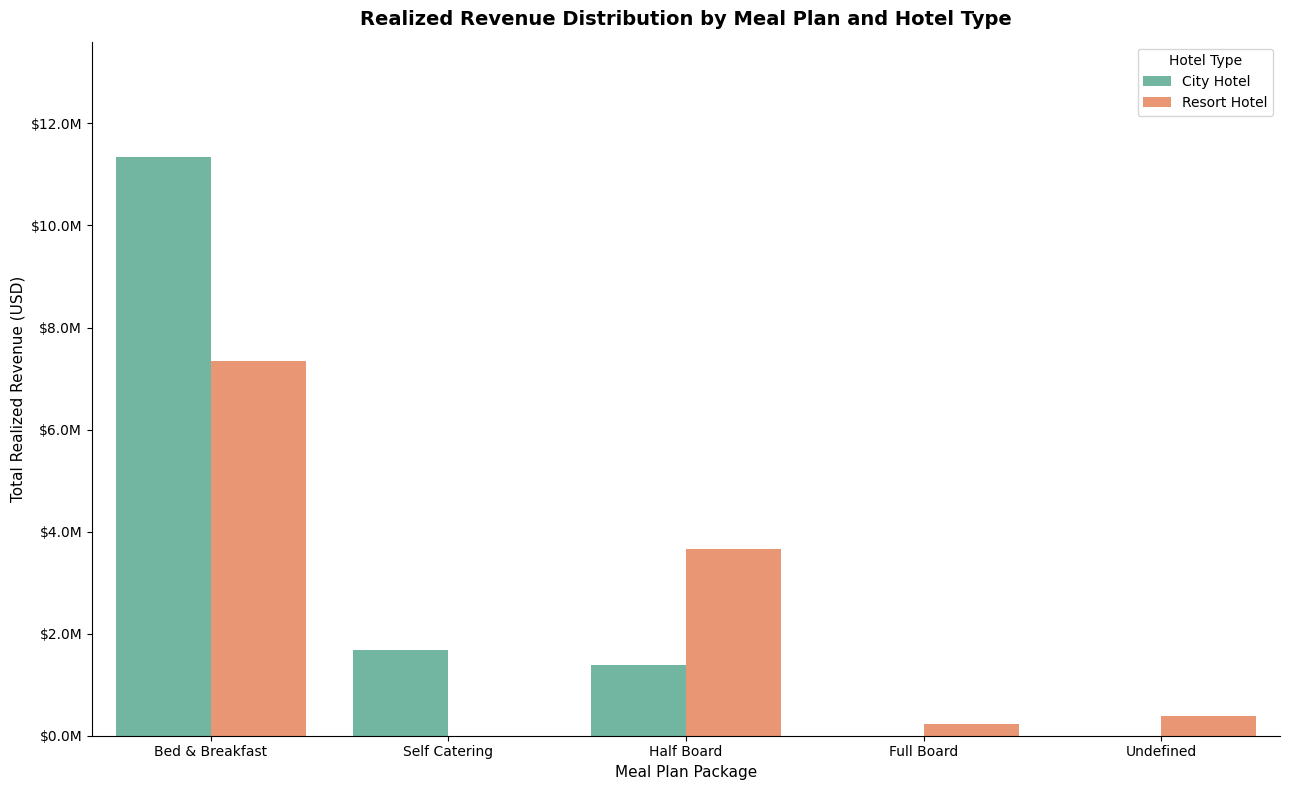

In [25]:
# Multidimensional revenue report crossing property type and meal plan package
master_hotel_revenue_df = duckdb.sql("""
SELECT
    r.hotel,
    cat.meal_plan,
    PRINTF('%,d', COUNT(*)) AS confirmed_bookings,
    PRINTF('$%,.2f', SUM(r.adr * (r.stays_in_week_nights + r.stays_in_weekend_nights))) AS total_revenue
FROM hotel_df AS r
INNER JOIN meal_catalog_df AS cat
    ON r.meal = cat.meal_code
WHERE r.is_canceled = 0
GROUP BY r.hotel, cat.meal_plan
ORDER BY r.hotel ASC, SUM(r.adr * (r.stays_in_week_nights + r.stays_in_weekend_nights)) DESC
""").df()

display(master_hotel_revenue_df)

# Convert formatted currency string to float for plotting
master_hotel_revenue_df['total_revenue_num'] = (
    master_hotel_revenue_df['total_revenue']
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

upper_y_limit = master_hotel_revenue_df['total_revenue_num'].max() * 1.2

plt.figure(figsize=(13, 8))
ax = sns.barplot(
    data=master_hotel_revenue_df,
    x='meal_plan',
    y='total_revenue_num',
    hue='hotel',
    palette='Set2'
)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'${x / 1_000_000:.1f}M'))

plt.title(
    'Realized Revenue Distribution by Meal Plan and Hotel Type',
    fontsize=14,
    pad=12,
    fontweight='bold'
)
plt.xlabel('Meal Plan Package', fontsize=11)
plt.ylabel('Total Realized Revenue (USD)', fontsize=11)
plt.ylim(0, upper_y_limit)
plt.legend(title='Hotel Type', loc='upper right')
sns.despine()
plt.tight_layout()
plt.savefig('revenue_by_meal_plan.png', dpi=300, bbox_inches='tight')
plt.show()